In [90]:
# ============================================================
# 0. IMPORTS
# ============================================================

import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import chi2_contingency

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    PrecisionRecallDisplay,
)

from xgboost import XGBClassifier

from imblearn.over_sampling import SMOTE

import mlflow
import mlflow.sklearn
import mlflow.xgboost


warnings.filterwarnings("ignore")

sns.set_style("darkgrid")

In [91]:
# ============================================================
# 1. LOAD DATA
# ============================================================

FILE_PATH = "default of credit card clients.xls"

df = pd.read_csv(FILE_PATH, header=1)

In [92]:
# ============================================================
# 2. BASIC DATASET INFORMATION
# ============================================================

print("\n========== FIRST 5 ROWS ==========")
print(df.head())

print("\n========== DATASET SHAPE ==========")
print(df.shape)

print("\n========== COLUMN NAMES ==========")
print(df.columns.tolist())

print("\n========== DATA TYPES ==========")
df.info()

print("\n========== DESCRIPTIVE STATISTICS ==========")
print(df.describe(include="all").T)


========== FIRST 5 ROWS ==========
   ID  LIMIT_BAL  SEX  EDUCATION  MARRIAGE  AGE  PAY_0  PAY_2  PAY_3  PAY_4  \
0   1      20000    2          2         1   24      2      2     -1     -1   
1   2     120000    2          2         2   26     -1      2      0      0   
2   3      90000    2          2         2   34      0      0      0      0   
3   4      50000    2          2         1   37      0      0      0      0   
4   5      50000    1          2         1   57     -1      0     -1      0   

   ...  BILL_AMT4  BILL_AMT5  BILL_AMT6  PAY_AMT1  PAY_AMT2  PAY_AMT3  \
0  ...          0          0          0         0       689         0   
1  ...       3272       3455       3261         0      1000      1000   
2  ...      14331      14948      15549      1518      1500      1000   
3  ...      28314      28959      29547      2000      2019      1200   
4  ...      20940      19146      19131      2000     36681     10000   

   PAY_AMT4  PAY_AMT5  PAY_AMT6  default payment n

In [93]:
# ============================================================
# 3. DEFINE COLUMNS
# ============================================================

TARGET = "default payment next month"

ID_COLUMNS = ["ID"]

CATEGORICAL_COLUMNS = ["SEX", "EDUCATION", "MARRIAGE"]

ORDINAL_COLUMNS = ["PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]

CONTINUOUS_COLUMNS = [
    "LIMIT_BAL",
    "AGE",
    "BILL_AMT1",
    "BILL_AMT2",
    "BILL_AMT3",
    "BILL_AMT4",
    "BILL_AMT5",
    "BILL_AMT6",
    "PAY_AMT1",
    "PAY_AMT2",
    "PAY_AMT3",
    "PAY_AMT4",
    "PAY_AMT5",
    "PAY_AMT6",
]


========== TARGET DISTRIBUTION ==========
default payment next month
0    23364
1     6636
Name: count, dtype: int64

Percentages:
default payment next month
0    77.88
1    22.12
Name: proportion, dtype: float64


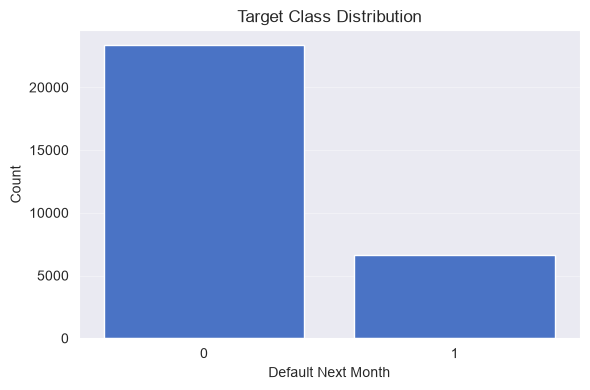

In [94]:
# ============================================================
# 4. TARGET DISTRIBUTION
# ============================================================

print("\n========== TARGET DISTRIBUTION ==========")

target_counts = df[TARGET].value_counts()

target_percentages = df[TARGET].value_counts(normalize=True) * 100

print(target_counts)

print("\nPercentages:")
print(target_percentages.round(2))


plt.figure(figsize=(6, 4))

sns.countplot(data=df, x=TARGET)

plt.title("Target Class Distribution")

plt.xlabel("Default Next Month")

plt.ylabel("Count")

plt.tight_layout()
plt.show()

In [95]:
# ============================================================
# 5. MISSING VALUES
# ============================================================

print("\n========== MISSING VALUES ==========")

missing_report = pd.DataFrame(
    {
        "missing_count": df.isnull().sum(),
        "missing_percentage": (df.isnull().mean() * 100).round(2),
    }
)


missing_report = missing_report[missing_report["missing_count"] > 0].sort_values(
    "missing_percentage", ascending=False
)


if missing_report.empty:
    print("No missing values found.")

else:
    print(missing_report)


========== MISSING VALUES ==========
No missing values found.


In [96]:
# ============================================================
# 6. DUPLICATES
# ============================================================

print("\n========== DUPLICATES ==========")

duplicate_count = df.duplicated().sum()

print("Duplicate rows:", duplicate_count)


========== DUPLICATES ==========
Duplicate rows: 0


In [97]:
# ============================================================
# 7. CATEGORICAL / ORDINAL VALUES
# ============================================================

print("\n========== CATEGORY VALUES ==========")

for column in CATEGORICAL_COLUMNS + ORDINAL_COLUMNS:
    print(f"\n--- {column} ---")

    print(df[column].value_counts(dropna=False).sort_index())


========== CATEGORY VALUES ==========

--- SEX ---
SEX
1    11888
2    18112
Name: count, dtype: int64

--- EDUCATION ---
EDUCATION
0       14
1    10585
2    14030
3     4917
4      123
5      280
6       51
Name: count, dtype: int64

--- MARRIAGE ---
MARRIAGE
0       54
1    13659
2    15964
3      323
Name: count, dtype: int64

--- PAY_0 ---
PAY_0
-2     2759
-1     5686
 0    14737
 1     3688
 2     2667
 3      322
 4       76
 5       26
 6       11
 7        9
 8       19
Name: count, dtype: int64

--- PAY_2 ---
PAY_2
-2     3782
-1     6050
 0    15730
 1       28
 2     3927
 3      326
 4       99
 5       25
 6       12
 7       20
 8        1
Name: count, dtype: int64

--- PAY_3 ---
PAY_3
-2     4085
-1     5938
 0    15764
 1        4
 2     3819
 3      240
 4       76
 5       21
 6       23
 7       27
 8        3
Name: count, dtype: int64

--- PAY_4 ---
PAY_4
-2     4348
-1     5687
 0    16455
 1        2
 2     3159
 3      180
 4       69
 5       35
 6        5
 

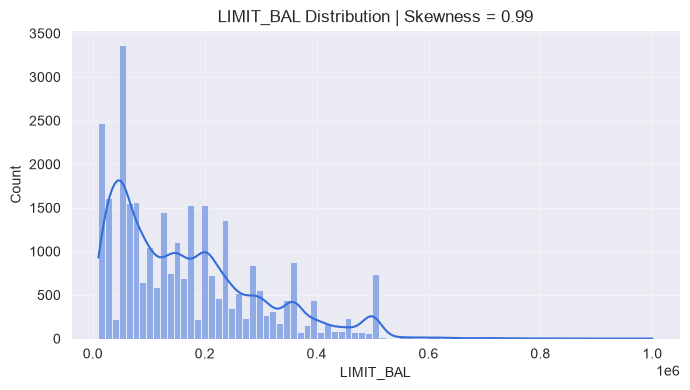

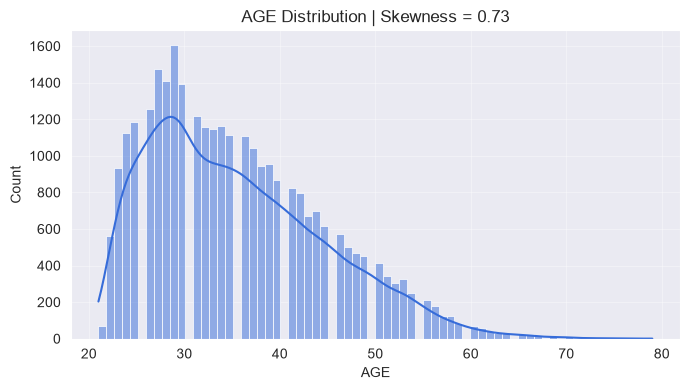

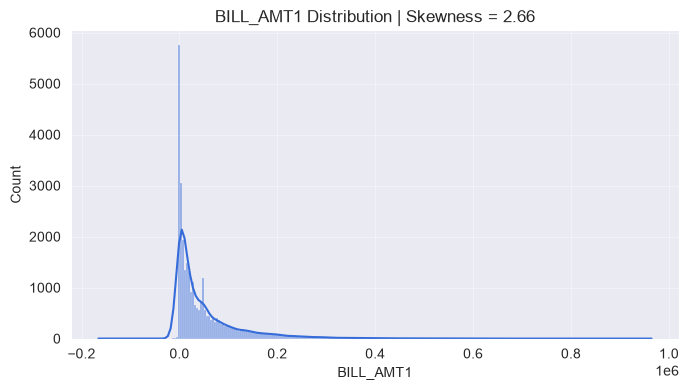

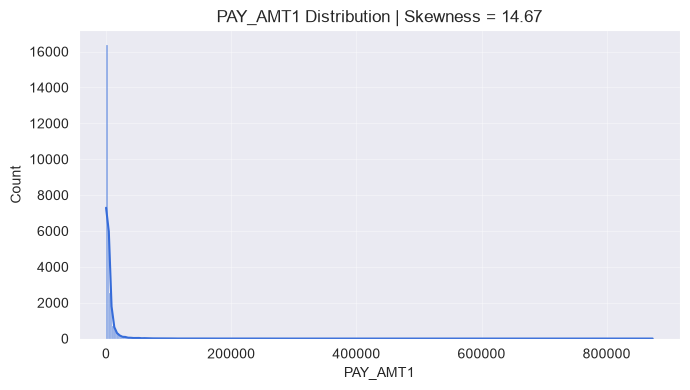

In [98]:
# ============================================================
# 8. CONTINUOUS FEATURE DISTRIBUTIONS
# ============================================================

important_continuous = ["LIMIT_BAL", "AGE", "BILL_AMT1", "PAY_AMT1"]


for column in important_continuous:
    plt.figure(figsize=(7, 4))

    sns.histplot(data=df, x=column, kde=True)

    skewness = df[column].skew()

    plt.title(f"{column} Distribution | Skewness = {skewness:.2f}")

    plt.tight_layout()
    plt.show()

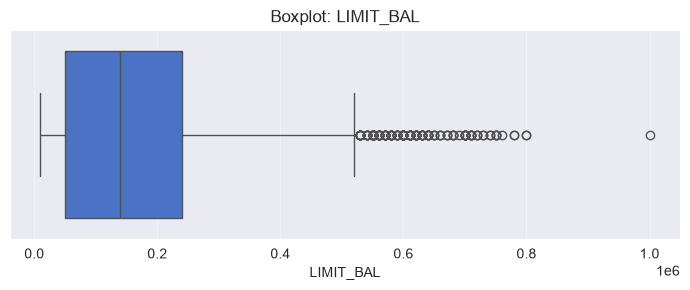

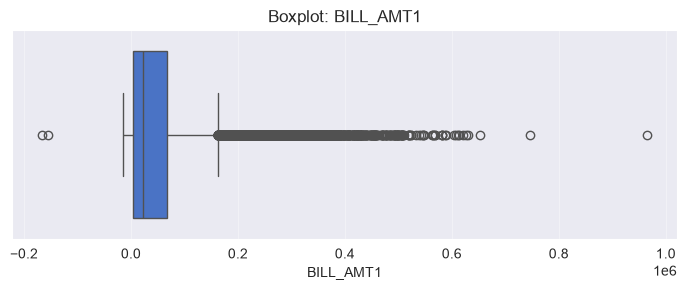

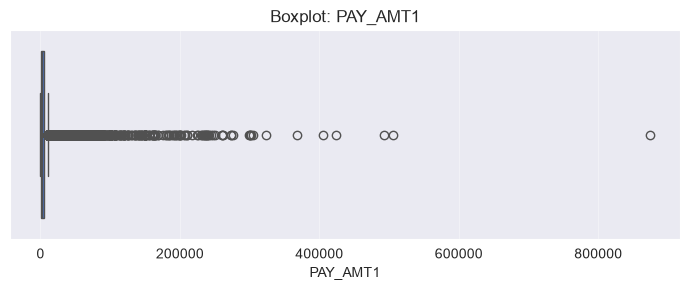

In [99]:
# ============================================================
# 9. BOXPLOTS
# ============================================================

for column in ["LIMIT_BAL", "BILL_AMT1", "PAY_AMT1"]:
    plt.figure(figsize=(7, 3))

    sns.boxplot(x=df[column])

    plt.title(f"Boxplot: {column}")

    plt.tight_layout()
    plt.show()

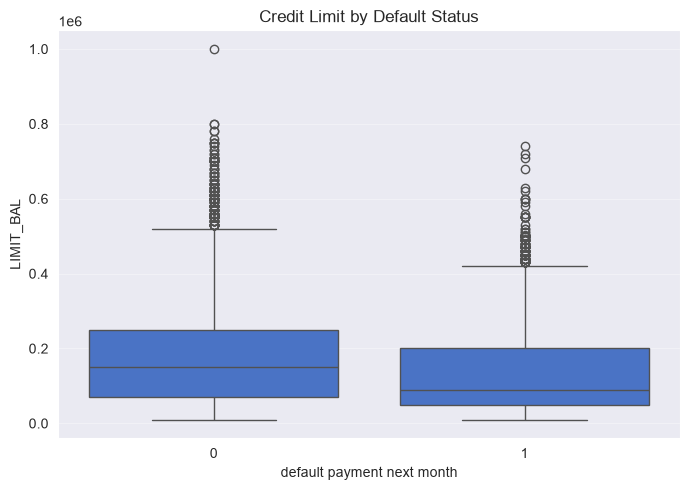

In [100]:
# ============================================================
# 10. NUMERIC FEATURE VS TARGET
# ============================================================

plt.figure(figsize=(7, 5))

sns.boxplot(data=df, x=TARGET, y="LIMIT_BAL")

plt.title("Credit Limit by Default Status")

plt.tight_layout()
plt.show()

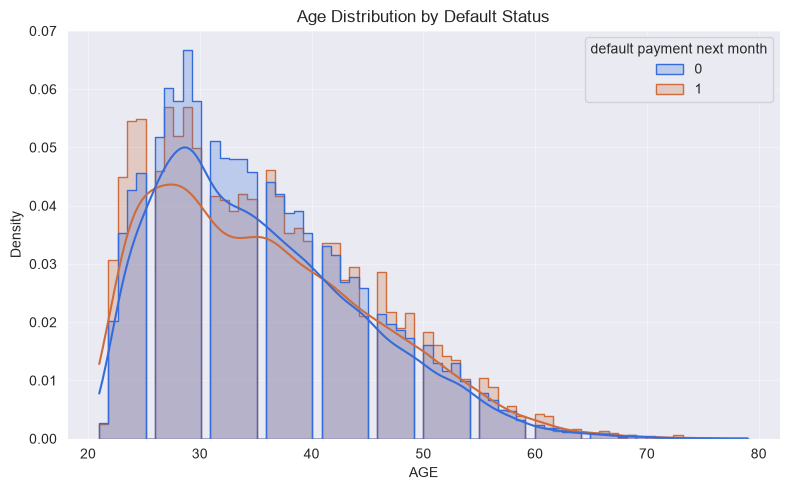

In [101]:
# ============================================================
# 11. NUMERIC DISTRIBUTION BY TARGET
# ============================================================

plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="AGE",
    hue=TARGET,
    kde=True,
    element="step",
    stat="density",
    common_norm=False,
)

plt.title("Age Distribution by Default Status")

plt.tight_layout()
plt.show()

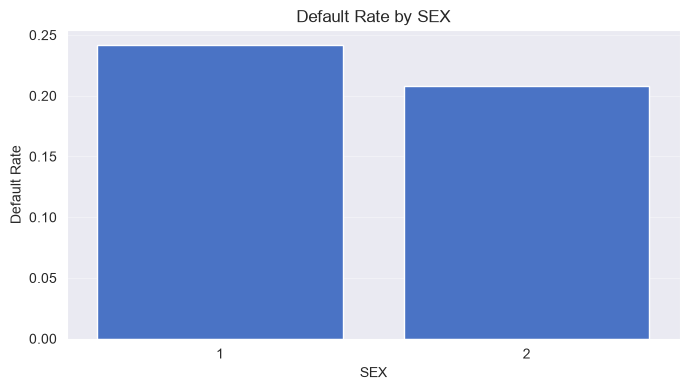

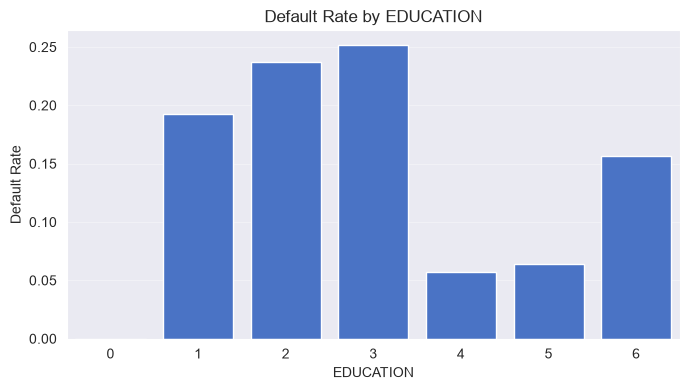

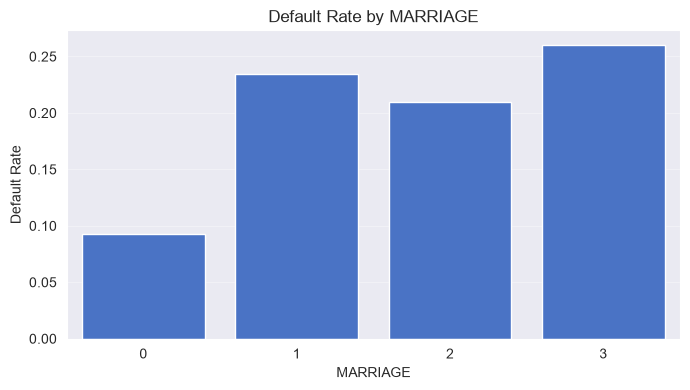

In [102]:
# ============================================================
# 12. CATEGORICAL FEATURES VS TARGET
# ============================================================

for column in CATEGORICAL_COLUMNS:
    default_rate = df.groupby(column)[TARGET].mean().reset_index()

    plt.figure(figsize=(7, 4))

    sns.barplot(data=default_rate, x=column, y=TARGET)

    plt.title(f"Default Rate by {column}")

    plt.ylabel("Default Rate")

    plt.tight_layout()
    plt.show()

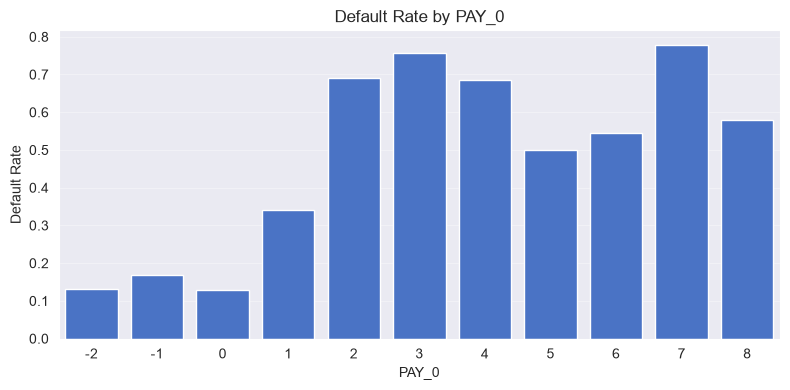

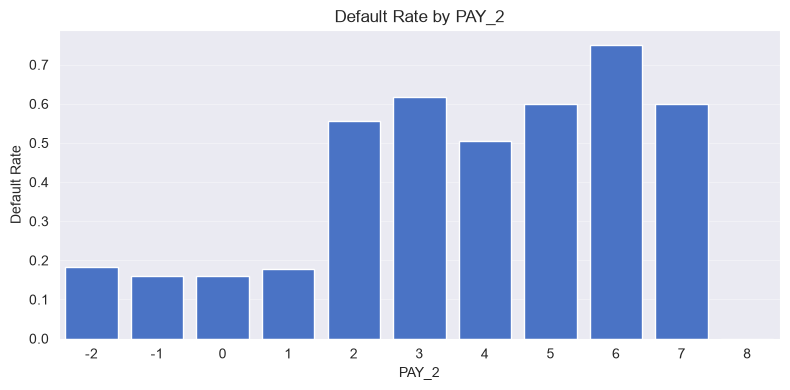

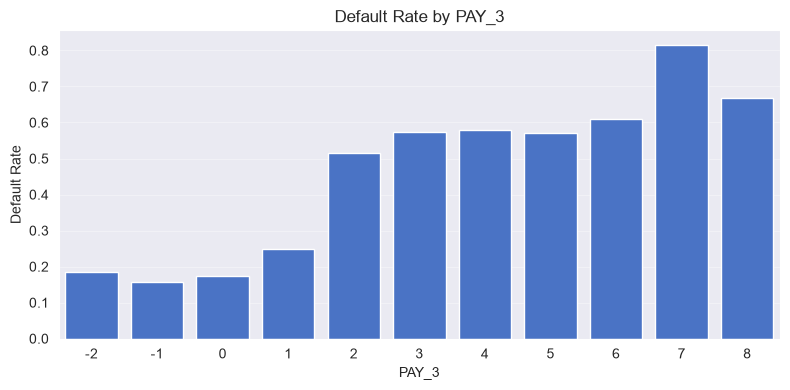

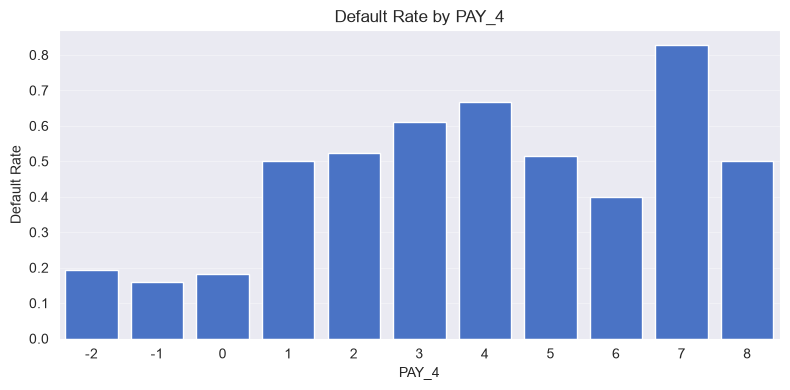

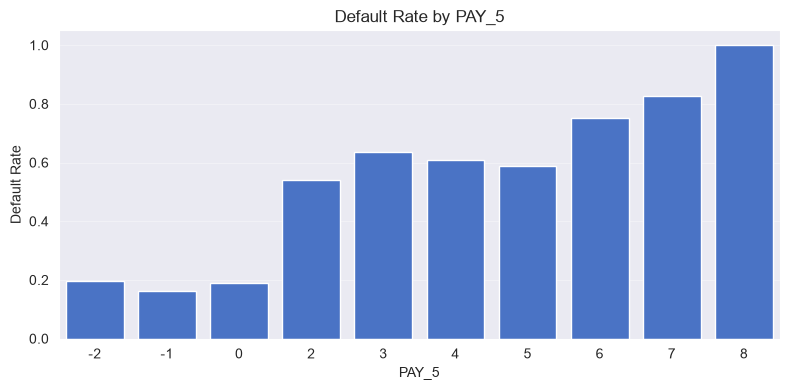

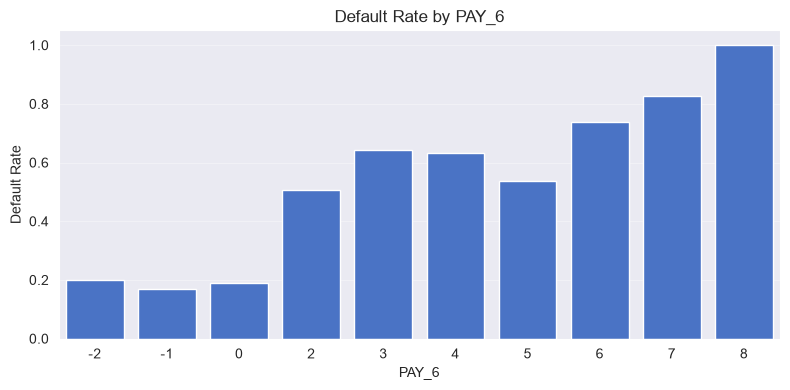

In [103]:
# ============================================================
# 13. ORDINAL FEATURES VS TARGET
# ============================================================

for column in ORDINAL_COLUMNS:
    default_rate = df.groupby(column)[TARGET].mean().reset_index()

    plt.figure(figsize=(8, 4))

    sns.barplot(data=default_rate, x=column, y=TARGET)

    plt.title(f"Default Rate by {column}")

    plt.ylabel("Default Rate")

    plt.tight_layout()
    plt.show()

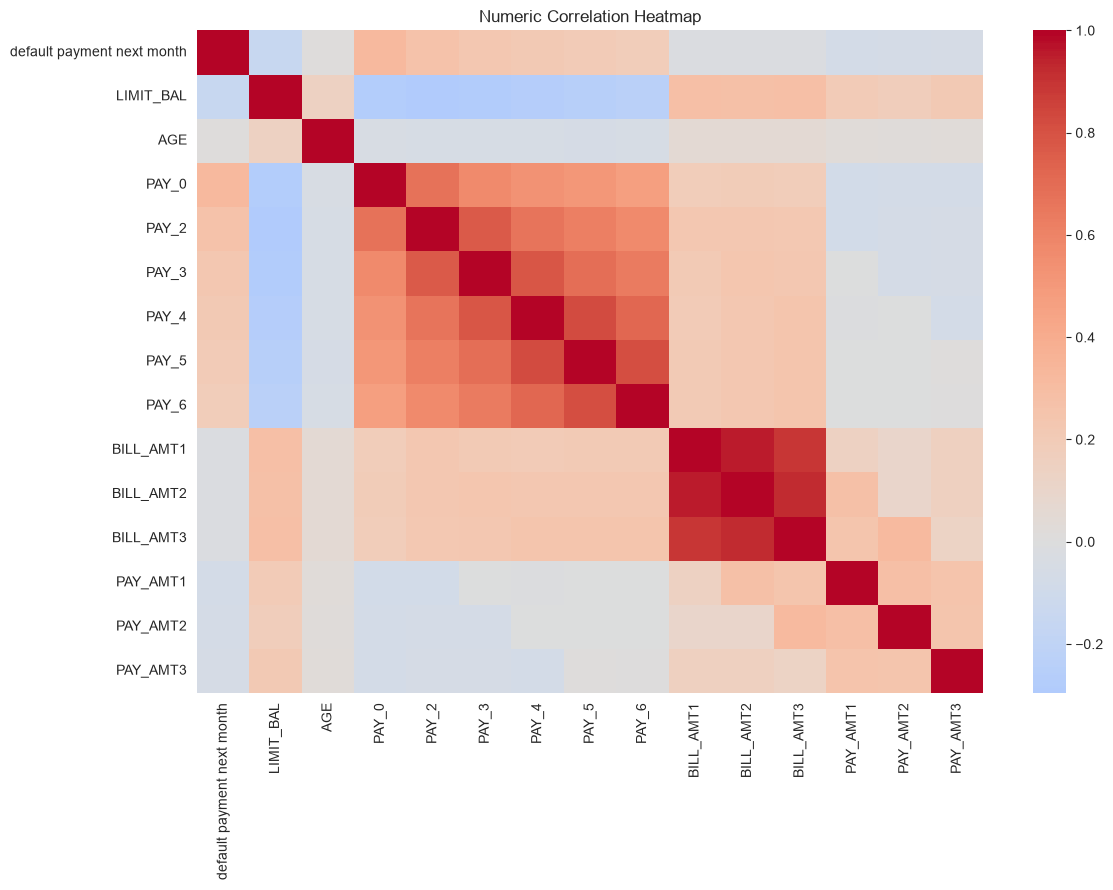

In [104]:
# ============================================================
# 14. NUMERIC CORRELATION
# ============================================================

correlation_columns = [
    TARGET,
    "LIMIT_BAL",
    "AGE",
    "PAY_0",
    "PAY_2",
    "PAY_3",
    "PAY_4",
    "PAY_5",
    "PAY_6",
    "BILL_AMT1",
    "BILL_AMT2",
    "BILL_AMT3",
    "PAY_AMT1",
    "PAY_AMT2",
    "PAY_AMT3",
]


corr_matrix = df[correlation_columns].corr()


plt.figure(figsize=(12, 9))

sns.heatmap(corr_matrix, cmap="coolwarm", center=0)

plt.title("Numeric Correlation Heatmap")

plt.tight_layout()
plt.show()

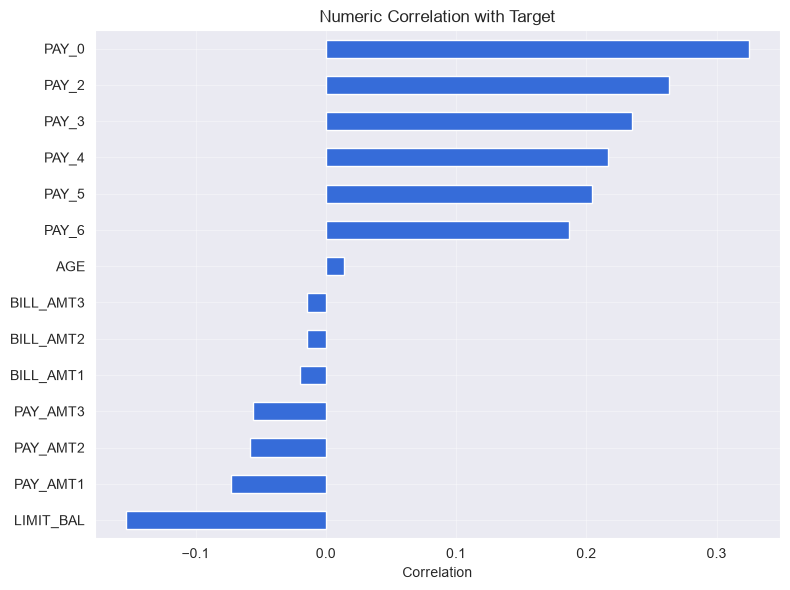

In [105]:
# ============================================================
# 15. NUMERIC CORRELATION WITH TARGET
# ============================================================

target_corr = corr_matrix[TARGET].drop(TARGET).sort_values()


plt.figure(figsize=(8, 6))

target_corr.plot(kind="barh")

plt.title("Numeric Correlation with Target")

plt.xlabel("Correlation")

plt.tight_layout()
plt.show()

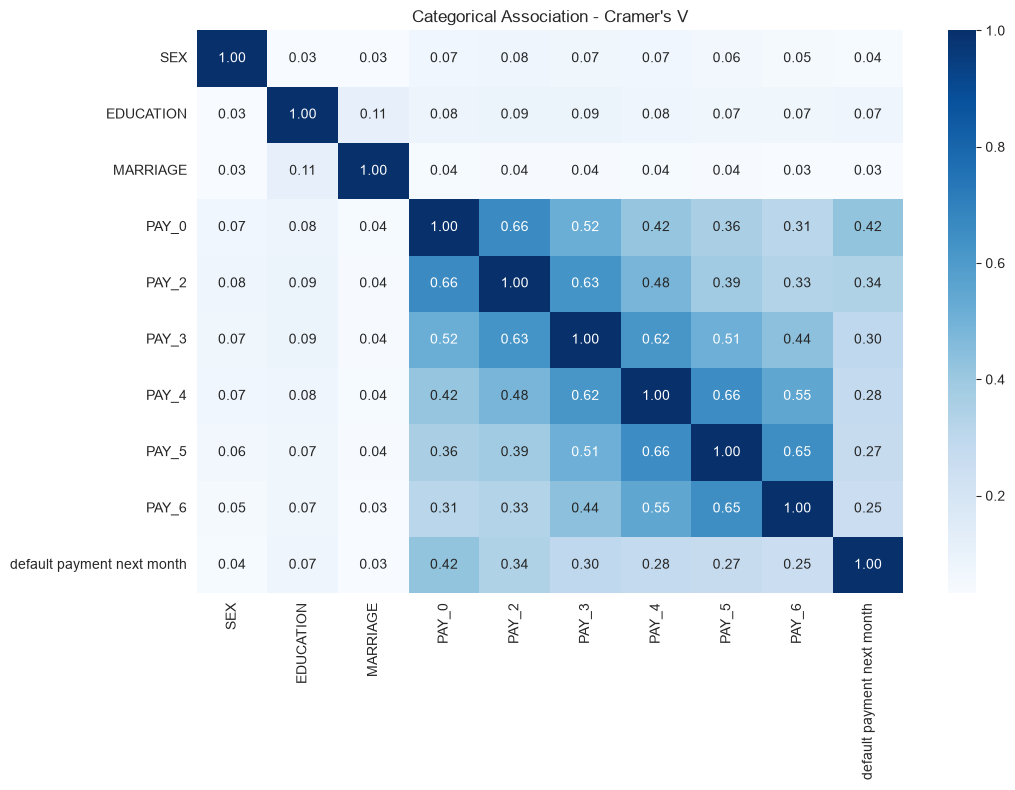

In [106]:
# ============================================================
# 16. CRAMER'S V
# ============================================================


def cramers_v(x, y):

    table = pd.crosstab(x, y)

    chi2 = chi2_contingency(table)[0]

    n = table.to_numpy().sum()

    rows, columns = table.shape

    denominator = min(rows - 1, columns - 1)

    if denominator == 0:
        return 0

    return np.sqrt((chi2 / n) / denominator)


categorical_analysis_columns = CATEGORICAL_COLUMNS + ORDINAL_COLUMNS + [TARGET]


cramers_matrix = pd.DataFrame(
    index=categorical_analysis_columns,
    columns=categorical_analysis_columns,
    dtype=float,
)


for col1 in categorical_analysis_columns:
    for col2 in categorical_analysis_columns:
        cramers_matrix.loc[col1, col2] = cramers_v(df[col1], df[col2])


plt.figure(figsize=(11, 8))

sns.heatmap(cramers_matrix, annot=True, fmt=".2f", cmap="Blues")

plt.title("Categorical Association - Cramer's V")

plt.tight_layout()
plt.show()

In [107]:
# ============================================================
# 17. EDA SUMMARY
# ============================================================

print("\n========== EDA SUMMARY ==========")

print("Rows:", df.shape[0])

print("Columns:", df.shape[1])

print("Duplicates:", duplicate_count)

print("Positive class rate:", round(df[TARGET].mean() * 100, 2), "%")

print("Columns with missing values:", (df.isnull().sum() > 0).sum())


========== EDA SUMMARY ==========
Rows: 30000
Columns: 25
Duplicates: 0
Positive class rate: 22.12 %
Columns with missing values: 0


In [108]:
# ============================================================
# 18. FEATURES AND TARGET
# ============================================================

X = df.drop(columns=[TARGET] + ID_COLUMNS)

y = df[TARGET]

In [109]:
# ============================================================
# 19. TRAIN / VALIDATION / TEST SPLIT
# ============================================================

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=42
)


X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=42
)


print("\n========== SPLIT SHAPES ==========")

print("Train:", X_train.shape)

print("Validation:", X_val.shape)

print("Test:", X_test.shape)


========== SPLIT SHAPES ==========
Train: (21000, 23)
Validation: (4500, 23)
Test: (4500, 23)


In [110]:
# ============================================================
# 20. NUMERIC PREPROCESSING
# ============================================================

numeric_pipeline = Pipeline(
    [("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]
)

In [111]:
# ============================================================
# 21. CATEGORICAL PREPROCESSING
# ============================================================

categorical_pipeline = Pipeline(
    [
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore")),
    ]
)

In [112]:
# ============================================================
# 22. ORDINAL PREPROCESSING
# ============================================================

ordinal_pipeline = Pipeline([("imputer", SimpleImputer(strategy="most_frequent"))])

In [113]:
# ============================================================
# 23. COMBINE PREPROCESSING
# ============================================================

preprocessor = ColumnTransformer(
    [
        ("numeric", numeric_pipeline, CONTINUOUS_COLUMNS),
        ("categorical", categorical_pipeline, CATEGORICAL_COLUMNS),
        ("ordinal", ordinal_pipeline, ORDINAL_COLUMNS),
    ]
)

In [114]:
# ============================================================
# 24. FIT PREPROCESSING
# ============================================================

X_train_processed = preprocessor.fit_transform(X_train)


X_val_processed = preprocessor.transform(X_val)


X_test_processed = preprocessor.transform(X_test)


print("\n========== PROCESSED SHAPES ==========")

print("Train:", X_train_processed.shape)

print("Validation:", X_val_processed.shape)

print("Test:", X_test_processed.shape)


========== PROCESSED SHAPES ==========
Train: (21000, 33)
Validation: (4500, 33)
Test: (4500, 33)


In [115]:
# ============================================================
# 25. CLASS IMBALANCE
# ============================================================

negative_count = (y_train == 0).sum()

positive_count = (y_train == 1).sum()


scale_pos_weight = negative_count / positive_count


print("\n========== CLASS BALANCE ==========")

print("Negative:", negative_count)

print("Positive:", positive_count)

print("scale_pos_weight:", round(scale_pos_weight, 2))


========== CLASS BALANCE ==========
Negative: 16355
Positive: 4645
scale_pos_weight: 3.52


In [116]:
# ============================================================
# 26. MLFLOW SETUP
# ============================================================

mlflow.set_tracking_uri("http://localhost:5000")

mlflow.set_experiment("credit-default-classification")
mlflow.system_metrics.set_system_metrics_sampling_interval(1)

train_dataset = mlflow.data.from_numpy(
    X_train_processed, targets=y_train.to_numpy(), name="credit-default-train"
)
validation_dataset = mlflow.data.from_numpy(
    X_val_processed, targets=y_val.to_numpy(), name="credit-default-validation"
)
test_dataset = mlflow.data.from_numpy(
    X_test_processed, targets=y_test.to_numpy(), name="credit-default-test"
)

In [117]:
# ============================================================
# 27. EVALUATION FUNCTION
# ============================================================


def evaluate_model(model, X, y, model_name, threshold=0.5):

    with mlflow.start_span(
        "predict_probabilities", run_id=mlflow.active_run().info.run_id
    ) as span:
        span.set_inputs(
            {"model": model_name, "rows": len(X), "threshold": float(threshold)}
        )
        probabilities = model.predict_proba(X)[:, 1]
        span.set_outputs(
            {
                "probability_min": float(probabilities.min()),
                "probability_max": float(probabilities.max()),
            }
        )

    predictions = (probabilities >= threshold).astype(int)

    results = {
        "accuracy": accuracy_score(y, predictions),
        "precision": precision_score(y, predictions, zero_division=0),
        "recall": recall_score(y, predictions, zero_division=0),
        "f1": f1_score(y, predictions, zero_division=0),
        "roc_auc": roc_auc_score(y, probabilities),
        "pr_auc": average_precision_score(y, probabilities),
    }

    print(f"\n========== {model_name} ==========")

    for metric, value in results.items():
        print(f"{metric}: {value:.4f}")

    print("\nClassification Report:")

    print(classification_report(y, predictions, zero_division=0))

    print("\nConfusion Matrix:")

    print(confusion_matrix(y, predictions))

    mlflow.log_dict(
        {
            "model": model_name,
            "threshold": float(threshold),
            "classification_report": classification_report(
                y, predictions, output_dict=True, zero_division=0
            ),
            "confusion_matrix": confusion_matrix(y, predictions).tolist(),
        },
        "evaluation.json",
    )
    fig, ax = plt.subplots(figsize=(5, 4))
    ConfusionMatrixDisplay.from_predictions(y, predictions, ax=ax)
    ax.set_title(model_name)
    mlflow.log_figure(fig, "confusion_matrix.png")
    plt.close(fig)

    return results


def fit_with_trace(model, X, y):
    with mlflow.start_span("fit_model", run_id=mlflow.active_run().info.run_id) as span:
        span.set_inputs(
            {"estimator": type(model).__name__, "rows": len(y), "features": X.shape[1]}
        )
        model.fit(X, y)
        span.set_outputs({"fitted": True})
    return model

In [118]:
# ============================================================
# 28. LOGISTIC REGRESSION + MLFLOW
# ============================================================

logistic_model = LogisticRegression(
    max_iter=1000, class_weight="balanced", random_state=42
)


with mlflow.start_run(run_name="logistic-regression", log_system_metrics=True):
    mlflow.log_input(train_dataset, context="training")
    mlflow.log_input(validation_dataset, context="validation")
    fit_with_trace(logistic_model, X_train_processed, y_train)

    logistic_results = evaluate_model(
        logistic_model, X_val_processed, y_val, "Logistic Regression"
    )

    mlflow.log_params(
        {
            "model_type": "LogisticRegression",
            "max_iter": 1000,
            "class_weight": "balanced",
        }
    )

    mlflow.log_metrics(logistic_results)

    mlflow.sklearn.log_model(sk_model=logistic_model, name="model")

2026/10/12 08:49:26 INFO mlflow.system_metrics.system_metrics_monitor: Skip logging GPU metrics. Set logger level to DEBUG for more details.
2026/10/12 08:49:26 INFO mlflow.system_metrics.system_metrics_monitor: Started monitoring system metrics.



========== Logistic Regression ==========
accuracy: 0.6811
precision: 0.3709
recall: 0.6352
f1: 0.4683
roc_auc: 0.7148
pr_auc: 0.5002

Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.69      0.77      3505
           1       0.37      0.64      0.47       995

    accuracy                           0.68      4500
   macro avg       0.62      0.66      0.62      4500
weighted avg       0.76      0.68      0.71      4500


Confusion Matrix:
[[2433 1072]
 [ 363  632]]


2026/10/12 08:49:30 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.
2026/10/12 08:49:30 INFO mlflow.system_metrics.system_metrics_monitor: Stopping system metrics monitoring...
2026/10/12 08:49:30 INFO mlflow.system_metrics.system_metrics_monitor: Successfully terminated system metrics monitoring!


🏃 View run logistic-regression at: http://localhost:5000/#/experiments/2/runs/7b0f519c47034aa8b4ef900a954ba17c
🧪 View experiment at: http://localhost:5000/#/experiments/2


In [119]:
# ============================================================
# 29. RANDOM FOREST + MLFLOW
# ============================================================

rf_model = RandomForestClassifier(
    n_estimators=300, max_depth=10, class_weight="balanced", random_state=42, n_jobs=-1
)


with mlflow.start_run(run_name="random-forest", log_system_metrics=True):
    mlflow.log_input(train_dataset, context="training")
    mlflow.log_input(validation_dataset, context="validation")
    fit_with_trace(rf_model, X_train_processed, y_train)

    rf_results = evaluate_model(rf_model, X_val_processed, y_val, "Random Forest")

    mlflow.log_params(
        {
            "model_type": "RandomForest",
            "n_estimators": 300,
            "max_depth": 10,
            "class_weight": "balanced",
        }
    )

    mlflow.log_metrics(rf_results)

    mlflow.sklearn.log_model(
        sk_model=rf_model, name="model", skops_trusted_types=["sklearn.tree._tree.Tree"]
    )

2026/10/12 08:49:30 INFO mlflow.system_metrics.system_metrics_monitor: Skip logging GPU metrics. Set logger level to DEBUG for more details.
2026/10/12 08:49:30 INFO mlflow.system_metrics.system_metrics_monitor: Started monitoring system metrics.



========== Random Forest ==========
accuracy: 0.7769
precision: 0.4961
recall: 0.5819
f1: 0.5356
roc_auc: 0.7763
pr_auc: 0.5511

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.83      0.85      3505
           1       0.50      0.58      0.54       995

    accuracy                           0.78      4500
   macro avg       0.69      0.71      0.69      4500
weighted avg       0.79      0.78      0.78      4500


Confusion Matrix:
[[2917  588]
 [ 416  579]]


2026/10/12 08:49:33 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.
2026/10/12 08:49:33 INFO mlflow.system_metrics.system_metrics_monitor: Stopping system metrics monitoring...
2026/10/12 08:49:33 INFO mlflow.system_metrics.system_metrics_monitor: Successfully terminated system metrics monitoring!


🏃 View run random-forest at: http://localhost:5000/#/experiments/2/runs/417328911a49468a824b0578a6eb5bb0
🧪 View experiment at: http://localhost:5000/#/experiments/2


[Trace(trace_id='tr-560be2b1dde546a9693510eb942b59e8'), Trace(trace_id='tr-2ab9511a30cbd83c4f3643eaf9bee27d'), Trace(trace_id='tr-893db2de066cd09e2c81f17ec6c00000'), Trace(trace_id='tr-75d1cd38df483ee53a1750f77d57ebad')]

In [120]:
# ============================================================
# 30. XGBOOST + MLFLOW
# ============================================================

xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1,
)


with mlflow.start_run(run_name="xgboost", log_system_metrics=True):
    mlflow.log_input(train_dataset, context="training")
    mlflow.log_input(validation_dataset, context="validation")
    fit_with_trace(xgb_model, X_train_processed, y_train)

    xgb_results = evaluate_model(xgb_model, X_val_processed, y_val, "XGBoost")

    mlflow.log_params(
        {
            "model_type": "XGBoost",
            "n_estimators": 300,
            "max_depth": 5,
            "learning_rate": 0.05,
            "subsample": 0.8,
            "colsample_bytree": 0.8,
            "scale_pos_weight": float(scale_pos_weight),
        }
    )

    mlflow.log_metrics(xgb_results)

    mlflow.xgboost.log_model(xgb_model, name="model")

2026/10/12 08:49:33 INFO mlflow.system_metrics.system_metrics_monitor: Skip logging GPU metrics. Set logger level to DEBUG for more details.
2026/10/12 08:49:33 INFO mlflow.system_metrics.system_metrics_monitor: Started monitoring system metrics.



========== XGBoost ==========
accuracy: 0.7638
precision: 0.4731
recall: 0.6010
f1: 0.5294
roc_auc: 0.7731
pr_auc: 0.5455

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.81      0.84      3505
           1       0.47      0.60      0.53       995

    accuracy                           0.76      4500
   macro avg       0.68      0.71      0.69      4500
weighted avg       0.79      0.76      0.77      4500


Confusion Matrix:
[[2839  666]
 [ 397  598]]


2026/10/12 08:49:35 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.
2026/10/12 08:49:36 INFO mlflow.system_metrics.system_metrics_monitor: Stopping system metrics monitoring...
2026/10/12 08:49:36 INFO mlflow.system_metrics.system_metrics_monitor: Successfully terminated system metrics monitoring!


🏃 View run xgboost at: http://localhost:5000/#/experiments/2/runs/9abcf4b8922a4ec09324652195bdc58d
🧪 View experiment at: http://localhost:5000/#/experiments/2


In [121]:
# ============================================================
# 31. OPTIONAL SMOTE
# ============================================================

smote = SMOTE(random_state=42)


X_train_smote, y_train_smote = smote.fit_resample(X_train_processed, y_train)


print("\n========== AFTER SMOTE ==========")

print(pd.Series(y_train_smote).value_counts())


========== AFTER SMOTE ==========
default payment next month
0    16355
1    16355
Name: count, dtype: int64


In [122]:
# ============================================================
# 32. LOGISTIC REGRESSION + SMOTE + MLFLOW
# ============================================================

logistic_smote_model = LogisticRegression(max_iter=1000, random_state=42)


with mlflow.start_run(run_name="logistic-regression-smote", log_system_metrics=True):
    mlflow.log_input(
        mlflow.data.from_numpy(
            X_train_smote,
            targets=np.asarray(y_train_smote),
            name="credit-default-train-smote",
        ),
        context="training",
    )
    mlflow.log_input(validation_dataset, context="validation")
    fit_with_trace(logistic_smote_model, X_train_smote, y_train_smote)

    smote_results = evaluate_model(
        logistic_smote_model, X_val_processed, y_val, "Logistic Regression + SMOTE"
    )

    mlflow.log_params(
        {
            "model_type": "LogisticRegression",
            "imbalance_strategy": "SMOTE",
            "max_iter": 1000,
        }
    )

    mlflow.log_metrics(smote_results)

    mlflow.sklearn.log_model(sk_model=logistic_smote_model, name="model")

2026/10/12 08:49:36 INFO mlflow.system_metrics.system_metrics_monitor: Skip logging GPU metrics. Set logger level to DEBUG for more details.
2026/10/12 08:49:36 INFO mlflow.system_metrics.system_metrics_monitor: Started monitoring system metrics.



========== Logistic Regression + SMOTE ==========
accuracy: 0.6658
precision: 0.3568
recall: 0.6372
f1: 0.4574
roc_auc: 0.7163
pr_auc: 0.5014

Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.67      0.76      3505
           1       0.36      0.64      0.46       995

    accuracy                           0.67      4500
   macro avg       0.61      0.66      0.61      4500
weighted avg       0.75      0.67      0.69      4500


Confusion Matrix:
[[2362 1143]
 [ 361  634]]


2026/10/12 08:49:38 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.
2026/10/12 08:49:38 INFO mlflow.system_metrics.system_metrics_monitor: Stopping system metrics monitoring...
2026/10/12 08:49:38 INFO mlflow.system_metrics.system_metrics_monitor: Successfully terminated system metrics monitoring!


🏃 View run logistic-regression-smote at: http://localhost:5000/#/experiments/2/runs/c817783d1d0d429d9674b6ed193afe9c
🧪 View experiment at: http://localhost:5000/#/experiments/2


[Trace(trace_id='tr-8abc3e567ce8cc2f38e443e56ac93275'), Trace(trace_id='tr-cf417c1beff2d02318ee7faee05611ec'), Trace(trace_id='tr-e516093af38c4cf05bbb8b5814cf7aeb'), Trace(trace_id='tr-993b3d8c49cae2599282c84bd1a6dc95')]

In [123]:
# ============================================================
# 33. MODEL COMPARISON
# ============================================================

results_df = pd.DataFrame(
    [
        {"model": "Logistic Regression", **logistic_results},
        {"model": "Random Forest", **rf_results},
        {"model": "XGBoost", **xgb_results},
        {"model": "Logistic + SMOTE", **smote_results},
    ]
)


results_df = results_df.sort_values("pr_auc", ascending=False)


print("\n========== MODEL COMPARISON ==========")

print(results_df)


========== MODEL COMPARISON ==========
                 model  accuracy  precision    recall        f1   roc_auc  \
1        Random Forest  0.776889   0.496144  0.581910  0.535615  0.776339   
2              XGBoost  0.763778   0.473101  0.601005  0.529438  0.773131   
3     Logistic + SMOTE  0.665778   0.356781  0.637186  0.457431  0.716316   
0  Logistic Regression  0.681111   0.370892  0.635176  0.468322  0.714807   

     pr_auc  
1  0.551142  
2  0.545529  
3  0.501405  
0  0.500182  


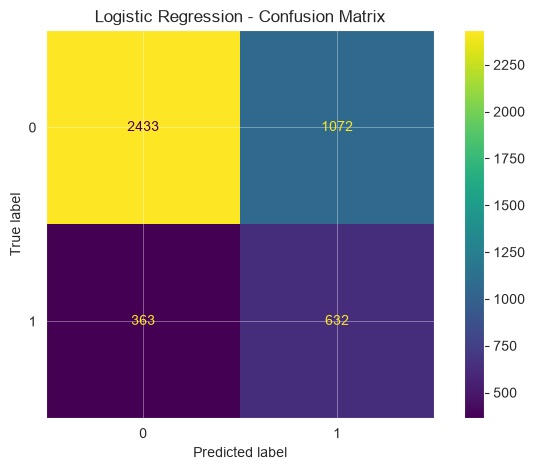

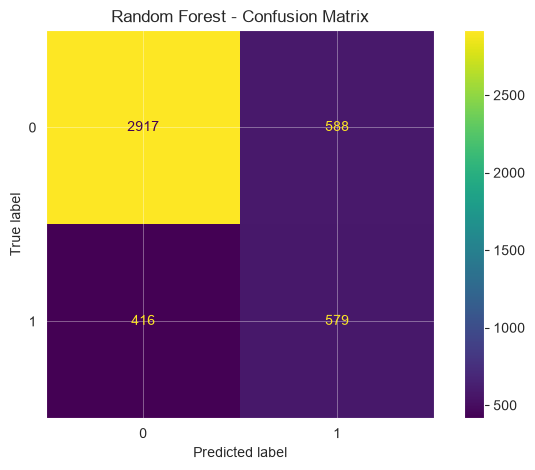

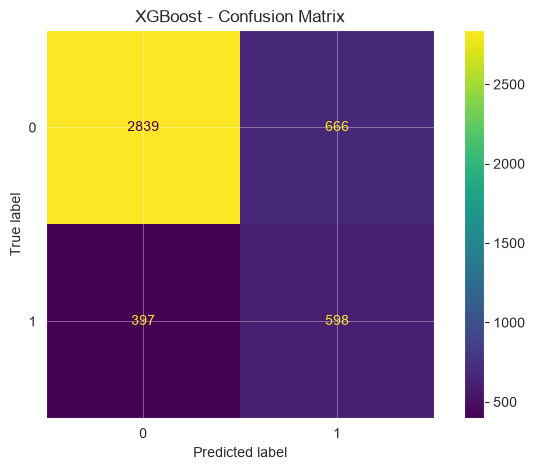

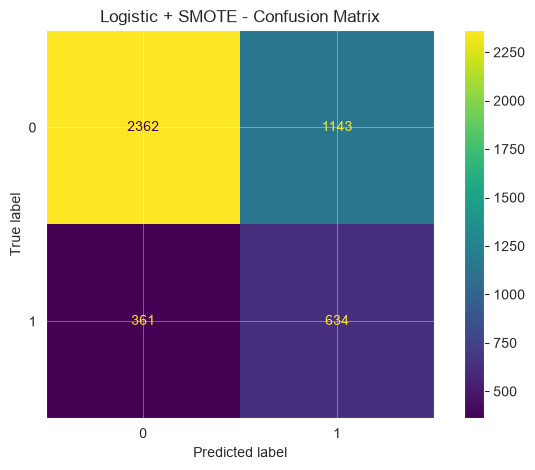

In [124]:
# ============================================================
# 34. CONFUSION MATRICES
# ============================================================

models = {
    "Logistic Regression": logistic_model,
    "Random Forest": rf_model,
    "XGBoost": xgb_model,
    "Logistic + SMOTE": logistic_smote_model,
}


for name, model in models.items():
    ConfusionMatrixDisplay.from_estimator(model, X_val_processed, y_val)

    plt.title(f"{name} - Confusion Matrix")

    plt.tight_layout()
    plt.show()

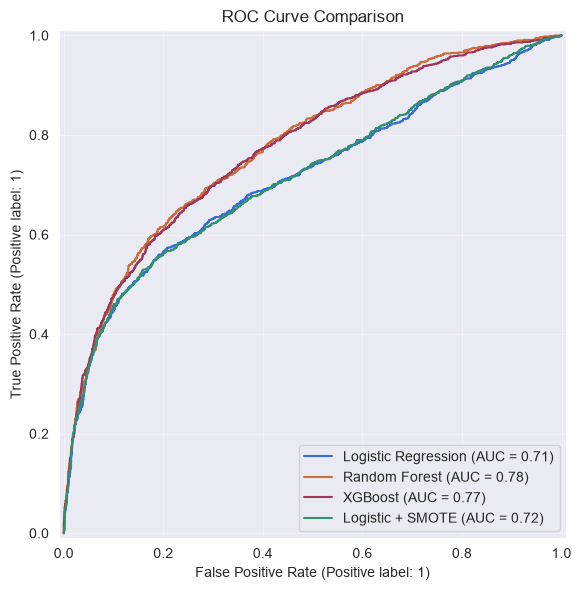

In [125]:
# ============================================================
# 35. ROC CURVES
# ============================================================

fig, ax = plt.subplots(figsize=(8, 6))


for name, model in models.items():
    RocCurveDisplay.from_estimator(model, X_val_processed, y_val, name=name, ax=ax)


plt.title("ROC Curve Comparison")

plt.tight_layout()
plt.show()

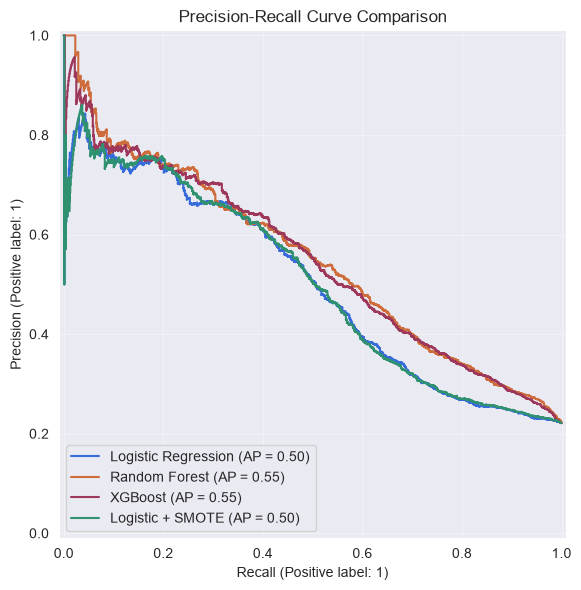

In [126]:
# ============================================================
# 36. PRECISION-RECALL CURVES
# ============================================================

fig, ax = plt.subplots(figsize=(8, 6))


for name, model in models.items():
    PrecisionRecallDisplay.from_estimator(
        model, X_val_processed, y_val, name=name, ax=ax
    )


plt.title("Precision-Recall Curve Comparison")

plt.tight_layout()
plt.show()

In [127]:
# ============================================================
# 37. SELECT BEST MODEL
# ============================================================

print("\n========== VALIDATION RESULTS ==========")

print(results_df)


# Change this after comparing validation results
best_model = xgb_model

best_model_name = "XGBoost"


========== VALIDATION RESULTS ==========
                 model  accuracy  precision    recall        f1   roc_auc  \
1        Random Forest  0.776889   0.496144  0.581910  0.535615  0.776339   
2              XGBoost  0.763778   0.473101  0.601005  0.529438  0.773131   
3     Logistic + SMOTE  0.665778   0.356781  0.637186  0.457431  0.716316   
0  Logistic Regression  0.681111   0.370892  0.635176  0.468322  0.714807   

     pr_auc  
1  0.551142  
2  0.545529  
3  0.501405  
0  0.500182  


In [128]:
# ============================================================
# 38. THRESHOLD TUNING
# ============================================================

probabilities = best_model.predict_proba(X_val_processed)[:, 1]


threshold_results = []


for threshold in np.arange(0.10, 0.91, 0.05):
    predictions = (probabilities >= threshold).astype(int)

    threshold_results.append(
        {
            "threshold": threshold,
            "precision": precision_score(y_val, predictions, zero_division=0),
            "recall": recall_score(y_val, predictions, zero_division=0),
            "f1": f1_score(y_val, predictions, zero_division=0),
        }
    )


threshold_df = pd.DataFrame(threshold_results)


print("\n========== THRESHOLD RESULTS ==========")

print(threshold_df)


========== THRESHOLD RESULTS ==========
    threshold  precision    recall        f1
0        0.10   0.229638  0.988945  0.372727
1        0.15   0.246942  0.973869  0.393983
2        0.20   0.265683  0.940704  0.414343
3        0.25   0.286774  0.893467  0.434188
4        0.30   0.316323  0.847236  0.460656
5        0.35   0.348492  0.777889  0.481343
6        0.40   0.388489  0.705528  0.501071
7        0.45   0.433177  0.648241  0.519324
8        0.50   0.473101  0.601005  0.529438
9        0.55   0.505587  0.545729  0.524891
10       0.60   0.551991  0.501508  0.525540
11       0.65   0.586873  0.458291  0.514673
12       0.70   0.627481  0.413065  0.498182
13       0.75   0.645683  0.360804  0.462927
14       0.80   0.683761  0.321608  0.437457
15       0.85   0.704188  0.270352  0.390704
16       0.90   0.754808  0.157789  0.261014


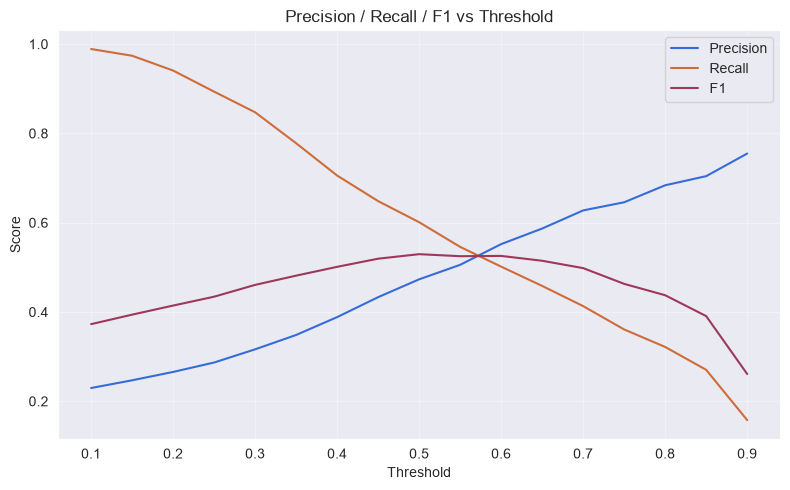

In [129]:
# ============================================================
# 39. THRESHOLD PLOT
# ============================================================

plt.figure(figsize=(8, 5))


plt.plot(threshold_df["threshold"], threshold_df["precision"], label="Precision")


plt.plot(threshold_df["threshold"], threshold_df["recall"], label="Recall")


plt.plot(threshold_df["threshold"], threshold_df["f1"], label="F1")


plt.xlabel("Threshold")

plt.ylabel("Score")

plt.title("Precision / Recall / F1 vs Threshold")

plt.legend()

plt.tight_layout()
plt.show()

In [130]:
# ============================================================
# 40. SELECT BEST THRESHOLD
# ============================================================

best_threshold_row = threshold_df.loc[threshold_df["f1"].idxmax()]


best_threshold = best_threshold_row["threshold"]


print("\nBest threshold:", round(best_threshold, 2))


Best threshold: 0.5


In [131]:
# ============================================================
# 41. FINAL TEST EVALUATION + MLFLOW
# ============================================================

with mlflow.start_run(run_name="final-selected-model", log_system_metrics=True):
    mlflow.log_input(train_dataset, context="training")
    mlflow.log_input(validation_dataset, context="validation")
    mlflow.log_input(test_dataset, context="testing")
    final_results = evaluate_model(
        best_model,
        X_test_processed,
        y_test,
        f"Final {best_model_name}",
        threshold=best_threshold,
    )

    mlflow.log_param("selected_model", best_model_name)

    mlflow.log_param("decision_threshold", float(best_threshold))

    mlflow.log_metrics({f"test_{key}": value for key, value in final_results.items()})
    mlflow.log_table(results_df, "validation_model_comparison.json")
    mlflow.log_table(threshold_df, "validation_threshold_search.json")
    preprocessor_info = mlflow.sklearn.log_model(
        preprocessor, name="preprocessor", skops_trusted_types=["numpy.dtype"]
    )
    if best_model is xgb_model:
        model_info = mlflow.xgboost.log_model(best_model, name="selected_model")
    else:
        trusted_types = ["sklearn.tree._tree.Tree"] if best_model is rf_model else None
        model_info = mlflow.sklearn.log_model(
            best_model, name="selected_model", skops_trusted_types=trusted_types
        )
    mlflow.log_dict(
        {
            "model_uri": model_info.model_uri,
            "preprocessor_uri": preprocessor_info.model_uri,
            "threshold": float(best_threshold),
        },
        "deployment_manifest.json",
    )

2026/10/12 08:49:39 INFO mlflow.system_metrics.system_metrics_monitor: Skip logging GPU metrics. Set logger level to DEBUG for more details.
2026/10/12 08:49:39 INFO mlflow.system_metrics.system_metrics_monitor: Started monitoring system metrics.



========== Final XGBoost ==========
accuracy: 0.7696
precision: 0.4839
recall: 0.6185
f1: 0.5430
roc_auc: 0.7783
pr_auc: 0.5581

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.81      0.85      3504
           1       0.48      0.62      0.54       996

    accuracy                           0.77      4500
   macro avg       0.68      0.72      0.69      4500
weighted avg       0.79      0.77      0.78      4500


Confusion Matrix:
[[2847  657]
 [ 380  616]]


2026/10/12 08:49:39 WARNING mlflow.sklearn: Model was missing function: predict. Not logging python_function flavor!
2026/10/12 08:49:41 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.
2026/10/12 08:49:43 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.
2026/10/12 08:49:43 INFO mlflow.system_metrics.system_metrics_monitor: Stopping system metrics monitoring...
2026/10/12 08:49:43 INFO mlflow.system_metrics.system_metrics_monitor: Successfully terminated system metrics monitoring!


🏃 View run final-selected-model at: http://localhost:5000/#/experiments/2/runs/95244886cbdc47bdb5b12754e280f5f6
🧪 View experiment at: http://localhost:5000/#/experiments/2


Trace(trace_id='tr-8444eee8247100fa2834b3765e98041b')

In [132]:
# ============================================================
# 42. FINAL SUMMARY
# ============================================================

print("\n========== FINAL RESULT ==========")

print("Selected model:", best_model_name)

print("Selected threshold:", round(best_threshold, 2))

print("Test Precision:", round(final_results["precision"], 4))

print("Test Recall:", round(final_results["recall"], 4))

print("Test F1:", round(final_results["f1"], 4))

print("Test ROC-AUC:", round(final_results["roc_auc"], 4))

print("Test PR-AUC:", round(final_results["pr_auc"], 4))


========== FINAL RESULT ==========
Selected model: XGBoost
Selected threshold: 0.5
Test Precision: 0.4839
Test Recall: 0.6185
Test F1: 0.543
Test ROC-AUC: 0.7783
Test PR-AUC: 0.5581
